# Random numbers, sampling, and Monte Carlo integration
### A guided computational case study for beginning engineers

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 12 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/12_Monte_Carlo_Sampling_and_Integration.ipynb)

This notebook is a **self-study example**. Work through its cells in order. It introduces random-number generators, sampling from a specified distribution, simple Monte Carlo integration, and importance sampling. The physics and probability are kept elementary so that the programming choices remain visible. The only additional packages are NumPy and Matplotlib; a local installation can use `python -m pip install numpy matplotlib`.

The discussion draws on the author's slides *Monte Carlo Method, Parts 1 and 2* (Wang, 2025), which also cover advanced methods beyond this notebook. The examples and code here are newly written.

Its aim is to show how a mathematical description becomes an executable algorithm. You may run the `.ipynb` file in Jupyter, including through Anaconda, or transfer individual examples into Spyder scripts. The notebook keeps a fixed seed so its saved outputs can be checked without entering interactive input.

**How to read this notebook.** Predict an output before running a cell, then compare the prediction with the result. A fixed seed makes this particular sequence reproducible; it does not turn a random estimate into an exact answer. Each executable line has an adjacent explanatory comment. Long comments are intentional: they show both what the line does and why it belongs in the calculation.


<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 5, Efficiency |
| **Time** | about 55 min (about 110 min with exercises) |
| **Before this** | Notebooks 02–05 (loops, functions, dictionaries, NumPy); the idea of a probability. |
| **Essential** | Sections 1–7, including "One seed, two different ideas". |
| **Optional on a first reading** | Acceptance–rejection sampling in Section 2, hit-or-miss integration in Section 3, and the optional extensions at the end. |
| **Next** | 13, Molecular dynamics: an introduction. |

**You have understood this notebook if you can, without looking back:**

1. Sample a biased die from its cumulative probabilities.
2. Use inverse-transform sampling to draw exponentially distributed numbers, and check them against the exact curve.
3. Estimate an integral as (b − a) × the average of f, and give an error bar s/√N from a single run.
4. Explain why 100 times more points makes the error only about 10 times smaller.
5. Explain why importance sampling reduces the error, and why leaving out the weight gives a wrong answer with no error message.

**Not expected of you:** Proving the 1/√N law or the variance formulas.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## Learning route and Python connections

1. Generate reproducible uniform pseudo-random numbers and see why individual draws still vary.
2. Use a **list**, a **loop**, a **condition**, and a **dictionary** to sample a biased die.
3. Turn uniform draws into an exponential distribution using its cumulative distribution function (CDF).
4. Estimate an integral using the mean of function values at random points and quantify repeated-run variation.
5. Change the sampling distribution deliberately and correct the resulting estimate with importance weights.

| Course idea | Where it appears |
|:--|:--|
| Variables and types | `sample_count` is an integer, `estimate` is a float, and `accepted` is a Boolean. |
| Lists, indices, and dictionaries | Store outcomes, access the cumulative probabilities by index, and label counts by die face. |
| `for` and `while` loops | Draw many samples and, in an optional method, repeat proposals until enough are accepted. |
| `if` / `else` | Decide which outcome a uniform draw represents or whether a proposed point is accepted. |
| Functions | Make a sampler and an integrand reusable and independently testable. |
| Arrays and plots | NumPy evaluates many draws at once; Matplotlib visualizes their distribution. |

Random numbers generated by software are **pseudo-random**: an algorithm creates a sequence that has useful statistical properties. Use a local `numpy.random.Generator` and an explicit seed for a reproducible teaching experiment. Separate generators are used for separate comparisons so that one experiment does not silently change another.


## Python ideas used here

This map shows where each programming idea appears. The central route through Sections 1–4 uses the basic ideas. The others appear in the short extensions after Section 7, which can be skipped on a first reading.

| Python idea | Where it appears in this case study |
|:--|:--|
| Programming, arithmetic, variables and types | A mathematical expectation becomes an algorithm; `seed`, `sample_count`, `estimate`, `print`, `type`, arithmetic and `math` functions have distinct roles. |
| Branching and iteration | `for` counts die faces; `if` selects a face; `while` and a proposal limit prevent an endless rejection sampler. |
| Strings, approximate solutions and bisection | Output labels are strings; `math.isclose` handles floating-point checks; an optional bisection computation inverts an exponential CDF. |
| Functions and scope | `sample_die`, `integrand` and transformation functions separate tasks; parameters, return values, and local names make the program reusable. |
| Tuples and lists | Parallel face/probability lists, zero-based indices, `append`, slicing, tuple unpacking, aliasing and copying. |
| Recursion and dictionaries | `counts` maps face keys to integer values; an optional short recursive probability calculation is compared with iteration. |
| Testing and debugging | Boundary checks, `raise ValueError`, `assert`, a caught exception, and exact-integral regression tests. |
| Object-oriented programming | Optional sampler class packages a generator and its sampling method. |
| Classes and inheritance | Optional subclass overrides the sampling rule and uses `super()`; methods expose a small interface. |
| Program efficiency I | Count $N$ draws, examine elapsed time, and distinguish an $O(N)$ sample loop from a constant-time operation. |
| Program efficiency II | Compare a recursive probability calculation and an iterative one; separate algorithmic growth from a vectorized constant factor. |
| Searching and sorting | The die sampler linearly scans sorted cumulative endpoints; an optional bisection search finds the same face in $O(\log K)$ comparisons. |
| Python and other languages | NumPy evaluates whole arrays and Matplotlib displays results; the same mathematics could be implemented in compiled languages or MATLAB. |

Some useful tools do not belong inside every computation. For instance, the notebook uses no `input()` prompt because interactive input would prevent a reproducible *Run All*. In a separate script, `int(input('How many samples? '))` would convert a user's text response to an integer, and the program would need to validate that it is positive. Indentation in each code cell defines its blocks. A **syntax error** prevents execution; a **semantic error** such as omitting an importance weight may run without an exception yet produce the wrong estimate.


In [1]:
# Import mathematical functions, including the exponential and logarithm.
import math
# Import NumPy for reproducible generators and calculations on arrays.
import numpy as np
# Import Matplotlib for the distributions and numerical diagnostics.
import matplotlib.pyplot as plt
# Fix the default figure size so plots are legible in the notebook.
plt.rcParams['figure.figsize'] = (7.2, 3.8)
# Choose a seed that students can reuse to reproduce the examples.
seed = 2026
# Give the first experiment its own generator, rather than changing global state.
uniform_rng = np.random.default_rng(seed)
# Ask the generator for five real numbers in the half-open interval [0, 1).
first_five = uniform_rng.random(5)
# Show the resulting array and its floating-point data type.
print('First five U(0,1) draws:', np.round(first_five, 5))
# Show the data type of one draw, connecting the array to numerical values.
print('Data type of one draw:', type(first_five[0]).__name__)


First five U(0,1) draws: [0.17893 0.63991 0.46727 0.3705  0.35492]
Data type of one draw: float64


### One seed, two different ideas

The generator's seed determines the sequence. Reconstructing a generator with the same seed returns the same first values; drawing *again from the same generator* advances it. Individual uniform draws are not expected to be equal or evenly spaced. The property $U\sim U(0,1)$ describes their distribution across many draws, not a rule that forces a small sample to look perfectly uniform.


In [2]:
# Reconstruct a fresh generator at the original starting state.
repeated_rng = np.random.default_rng(seed)
# Draw five values from that fresh generator.
repeated_five = repeated_rng.random(5)
# Check whether identical seeds reproduce the entire first five-element array.
same_sequence = np.array_equal(first_five, repeated_five)
# Advance the original generator by taking a new group of five draws.
next_five = uniform_rng.random(5)
# Print the exact-repeat test and the new, later values separately.
print('Fresh generator with same seed repeats first five:', same_sequence)
# Display a second group from the original sequence.
print('Next five from original generator:', np.round(next_five, 5))
# Fail immediately if this elementary reproducibility test is broken.
assert same_sequence


Fresh generator with same seed repeats first five: True
Next five from original generator: [0.79052 0.90514 0.17735 0.65278 0.2983 ]


## 1. A biased die: sampling a discrete distribution

Suppose an unusual six-sided die has probabilities $P(1)=P(2)=P(3)=1/12$, $P(4)=1/6$, $P(5)=1/4$, and $P(6)=1/3$. These numbers are nonnegative and sum to one. To sample the die, divide the unit interval into six pieces with these lengths. A uniform draw lands in exactly one piece. The successive right endpoints are the *cumulative probabilities* $1/12$, $2/12$, $3/12$, $5/12$, $8/12$, and $1$.

This example is useful before any array-based shortcut: each line can be traced with the Python topics covered in class. In particular, the loop that builds cumulative probabilities is a running sum, and the `if` in `sample_die` maps a uniform number to an outcome. A draw exactly on a boundary belongs to the next interval under the `<` rule; for a continuous uniform distribution, an exact boundary has probability zero.


In [3]:
# Store the six possible integer outcomes in a list.
faces = [1, 2, 3, 4, 5, 6]
# Store the corresponding probabilities in matching list positions.
probabilities = [1/12, 1/12, 1/12, 1/6, 1/4, 1/3]
# Start an empty list for the cumulative right endpoints of the intervals.
cumulative = []
# Start a floating-point running total at zero probability.
running_total = 0.0
# Visit each face's probability in the same order as the face list.
for probability in probabilities:
    # Add this face's probability to the right endpoint of its interval.
    running_total += probability
    # Save the right endpoint for the subsequent lookup.
    cumulative.append(running_total)
# Check that the probabilities describe a valid complete distribution.
assert math.isclose(sum(probabilities), 1.0)
# Show plain Python numbers rather than NumPy scalar wrappers in the table.
print('Face and cumulative right endpoint:', [(faces[i], round(cumulative[i], 4)) for i in range(len(faces))])


Face and cumulative right endpoint: [(1, 0.0833), (2, 0.1667), (3, 0.25), (4, 0.4167), (5, 0.6667), (6, 1.0)]


In [4]:
# Give the single-draw die sampler an explicit input and output.
def sample_die(u):
    # State the function's input range and returned value as its specification.
    '''Map one uniform number in [0,1) to a biased integer die face.'''
    # Reject values outside the range returned by a uniform generator.
    if not 0.0 <= u < 1.0:
        # Raise an error rather than silently returning an invalid face.
        raise ValueError('The uniform input must satisfy 0 <= u < 1.')
    # Compare the draw with the right endpoint of each face's interval.
    for index in range(len(faces)):
        # The first endpoint strictly above u selects the associated face.
        if u < cumulative[index]:
            # Return the face, using the same index in both lists.
            return faces[index]
    # Report an inconsistent probability table if round-off leaves no interval.
    raise RuntimeError('No interval selected; check the probabilities.')
# Check the boundaries using known inputs before drawing a large sample.
assert [sample_die(u) for u in [0.0, 0.1, 0.3, 0.6, 0.9]] == [1, 2, 4, 5, 6]
# Print a few traceable input-output examples for manual inspection.
print([(u, sample_die(u)) for u in [0.0, 0.1, 0.3, 0.6, 0.9]])


[(0.0, 1), (0.1, 2), (0.3, 4), (0.6, 5), (0.9, 6)]


When we draw many times, the **observed frequency** for a face should usually be near its assigned probability, but need not equal it. A dictionary makes the counts easy to inspect. The values are integers because a count represents a number of outcomes. The expression `counts[face] / sample_count` produces a floating-point fraction.


In [5]:
# Give the die experiment a generator independent of the introductory display.
die_rng = np.random.default_rng(17)
# Use enough draws to see the expected trend without making the loop slow.
die_sample_count = 12000
# Initialize one dictionary entry for every possible face, even if unseen.
counts = {face: 0 for face in faces}
# Repeat the draw-and-count operation once for each trial.
for trial in range(die_sample_count):
    # Draw a uniform number from the die experiment's generator.
    uniform_value = die_rng.random()
    # Transform the uniform draw into one biased die face.
    face = sample_die(uniform_value)
    # Increase the integer count stored under that face's dictionary key.
    counts[face] += 1
# Transform the counts into observed relative frequencies in face order.
observed = [counts[face] / die_sample_count for face in faces]
# Print the header of a compact result table.
print('face  theoretical  observed')
# Iterate through aligned indices to compare each theoretical and observed value.
for index in range(len(faces)):
    # Print one die face and its two probability values to three decimals.
    print(f'{faces[index]:4d}  {probabilities[index]:11.3f}  {observed[index]:8.3f}')
# Confirm that precisely one face was counted on every draw.
assert sum(counts.values()) == die_sample_count


face  theoretical  observed
   1        0.083     0.085
   2        0.083     0.086
   3        0.083     0.081
   4        0.167     0.173
   5        0.250     0.248
   6        0.333     0.328


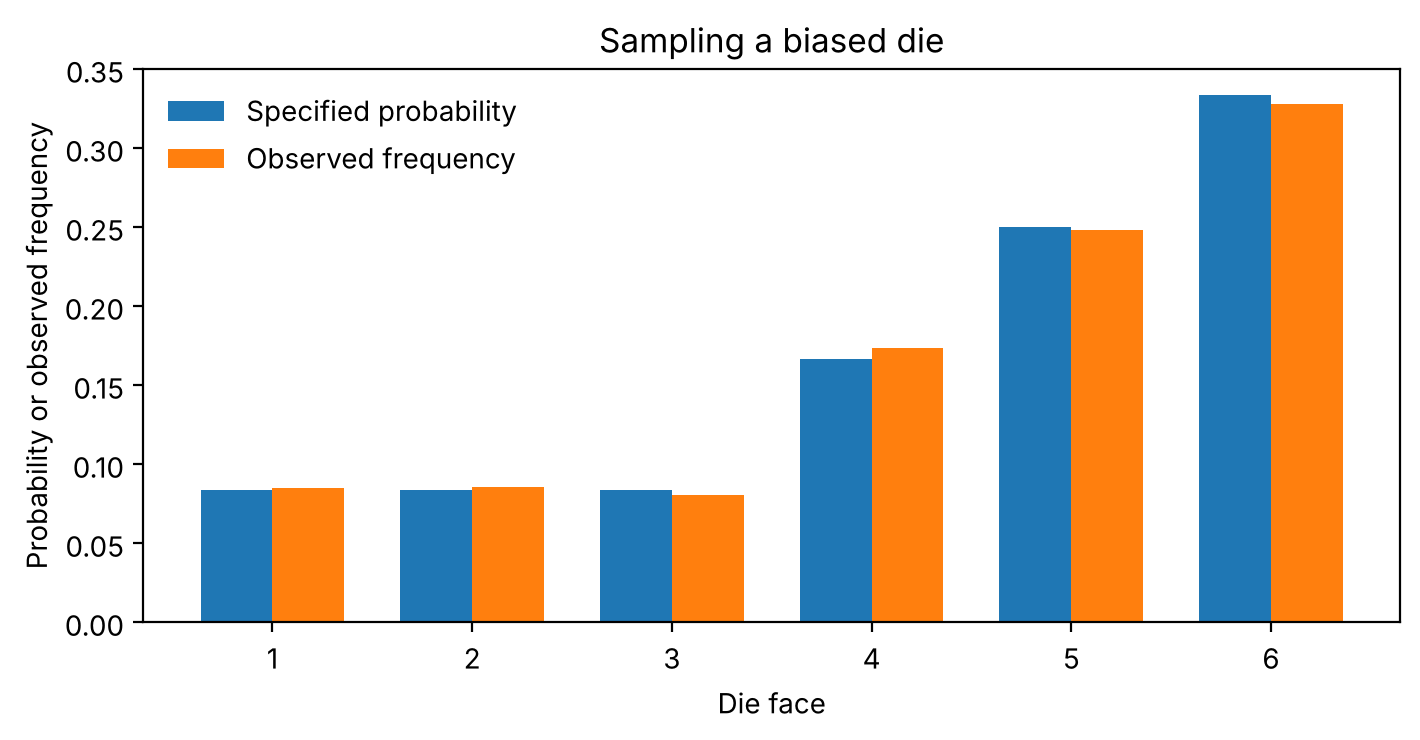

In [6]:
# Make two arrays of horizontal bar positions for the grouped comparison.
face_positions = np.arange(len(faces))
# Create one plot with an axis for both probability series.
fig, ax = plt.subplots()
# Plot the specified probabilities slightly to the left of each face position.
ax.bar(face_positions - 0.18, probabilities, width=0.36, label='Specified probability')
# Plot the observed frequencies slightly to the right for direct comparison.
ax.bar(face_positions + 0.18, observed, width=0.36, label='Observed frequency')
# Label the face positions with their integer values.
ax.set_xticks(face_positions, faces)
# State what each axis measures and what the figure compares.
ax.set(xlabel='Die face', ylabel='Probability or observed frequency', title='Sampling a biased die')
# Add labels for the two distinct bar series.
ax.legend(frameon=False)
# Prevent axis labels from overlapping the edge of the figure.
fig.tight_layout()
# Render the figure in the notebook.
plt.show()


**Stop and predict.** Which face is most likely? Does `faces[0]` refer to face zero or face one? What would break if the `faces` list were reordered but `probabilities` were not? Try a different sample count and compare the size of the frequency fluctuations; do not interpret a single sequence as a guarantee.

## 2. A continuous distribution: inverse-transform sampling

For a positive random quantity $X$ with an **exponential distribution** of rate $\lambda>0$, the probability density is $p(x)=\lambda e^{-\lambda x}$ for $x\ge0$. Its cumulative distribution is $F(x)=P(X\le x)=1-e^{-\lambda x}$. If $U$ is uniform on $[0,1)$, solve $F(x)=U$ for $x$:

$$X=F^{-1}(U)=-\frac{\log(1-U)}{\lambda}. $$

The result has the requested exponential distribution. We use `1 - u` so that a possible draw `u = 0` gives `x = 0`, avoiding `log(0)`; NumPy's generator does not return `u = 1`. The probability at a single endpoint is zero in the ideal continuous model. With $\lambda=2$, the theoretical mean is $1/\lambda=0.5$, and $P(X\le1)=1-e^{-2}$.


In [7]:
# Define a reusable scalar inverse-CDF transformation for positive rates.
def exponential_from_uniform(u, rate):
    # Document the sampler independently of how its inverse CDF is computed.
    '''Return one exponential sample from a uniform draw and positive rate.'''
    # Require a strictly positive rate for a valid exponential distribution.
    if rate <= 0:
        # Explain the invalid parameter instead of allowing division by zero.
        raise ValueError('The exponential rate must be positive.')
    # Require the input to lie in the generator's half-open uniform interval.
    if not 0.0 <= u < 1.0:
        # Explain why a draw of one cannot be transformed to a finite result.
        raise ValueError('The uniform input must satisfy 0 <= u < 1.')
    # Apply the inverse CDF to turn one uniform value into one exponential value.
    return -math.log(1.0 - u) / rate
# Check the exact result at a particularly simple uniform input.
assert exponential_from_uniform(0.0, 2.0) == 0.0
# Calculate an example by hand: -log(1-0.5)/2 = log(2)/2.
assert math.isclose(exponential_from_uniform(0.5, 2.0), math.log(2.0)/2.0)
# Display the hand-checkable input, output, and theoretical calculation.
print('u=0.5 maps to x=', round(exponential_from_uniform(0.5, 2.0), 6))


u=0.5 maps to x= 0.346574


In [8]:
# Give the continuous sampling experiment its own reproducible generator.
exponential_rng = np.random.default_rng(31)
# Set the positive rate parameter of the target distribution.
rate = 2.0
# Choose the number of independently generated exponential observations.
exponential_count = 20000
# Create a NumPy array of independent uniform values.
uniform_values = exponential_rng.random(exponential_count)
# Apply the inverse CDF to the complete array in one NumPy operation.
exponential_values = -np.log(1.0 - uniform_values) / rate
# Calculate the sample mean as a numerical check of the theoretical 1/rate.
exponential_mean = float(np.mean(exponential_values))
# Count the fraction of observations at or below x=1.
observed_probability = float(np.mean(exponential_values <= 1.0))
# Calculate the theoretical cumulative probability at x=1.
theoretical_probability = 1.0 - math.exp(-rate)
# Report the empirical and theoretical means side by side.
print(f'Mean: observed {exponential_mean:.4f}; theory {1/rate:.4f}')
# Report the empirical and theoretical cumulative probabilities.
print(f'P(X <= 1): observed {observed_probability:.4f}; theory {theoretical_probability:.4f}')
# Require all generated exponential values to remain in their valid range.
assert np.all(exponential_values >= 0.0)


Mean: observed 0.5024; theory 0.5000
P(X <= 1): observed 0.8652; theory 0.8647


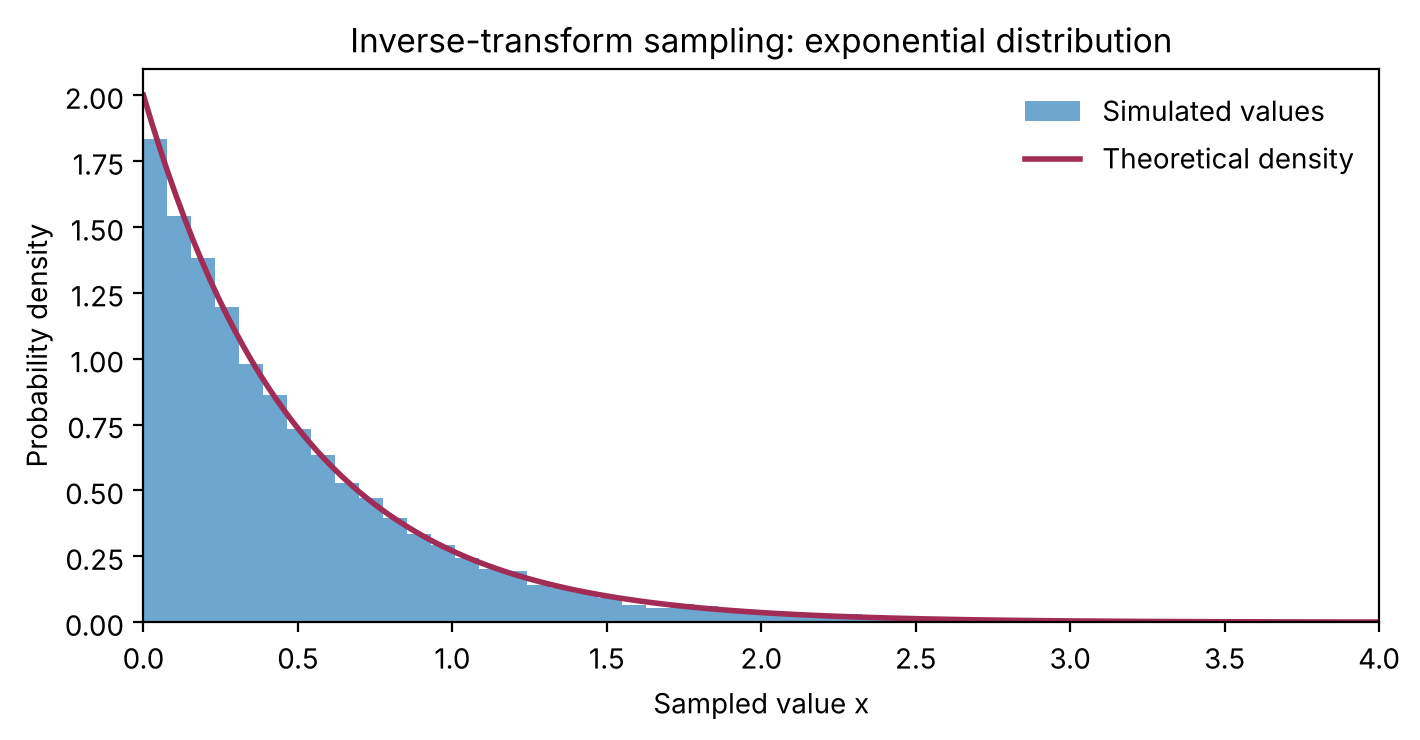

In [9]:
# Generate x coordinates for the known theoretical density curve.
grid = np.linspace(0.0, 4.0, 300)
# Evaluate the exponential density at each x coordinate.
density_curve = rate * np.exp(-rate * grid)
# Create a single panel for a density-normalized histogram and its theory.
fig, ax = plt.subplots()
# Normalize the histogram over the full sample, including its small right tail.
ax.hist(exponential_values, bins=55, density=True, alpha=0.65, label='Simulated values')
# Draw the theoretical density as a line on the same axes.
ax.plot(grid, density_curve, color='#a12c56', linewidth=2.0, label='Theoretical density')
# Label the generated quantity and the scale of the histogram.
ax.set(xlabel='Sampled value x', ylabel='Probability density', title='Inverse-transform sampling: exponential distribution')
# Display only the main part of the distribution without renormalizing its bins.
ax.set_xlim(0.0, 4.0)
# Identify which part of the plot is simulation and which is theory.
ax.legend(frameon=False)
# Adjust the panel to keep its labels in the figure area.
fig.tight_layout()
# Display the distribution comparison.
plt.show()


The histogram changes if we change its bin widths, and an individual sample can deviate from the curve. A density can exceed one at a point; it is the **area** over an interval that represents a probability. `np.mean(exponential_values <= 1.0)` illustrates another Python idea: the comparison creates Boolean values, and NumPy treats `True` as 1 and `False` as 0 when calculating their mean.


### The library functions as cross-checks

After understanding a sampling method, use tested library functions for routine work. `Generator.choice` accepts a list of outcomes and a matching list of probabilities. `Generator.exponential` uses a **scale**, which is the mean $1/\lambda$, rather than the rate $\lambda$. We do not expect two independently seeded methods to return the same individual samples. Their sample summaries should be consistent with the same specified distribution. The manual examples remain useful because they show exactly how lists, indices, a loop, and an inverse CDF map a uniform draw into another distribution.


In [10]:
# Give built-in distribution samplers their own independent random stream.
library_rng = np.random.default_rng(37)
# Draw die outcomes directly using the same face and probability lists.
library_faces = library_rng.choice(faces, size=12000, p=probabilities)
# Compute the fraction of direct-library die results equal to face six.
library_six_fraction = float(np.mean(library_faces == 6))
# Draw exponential values with scale equal to the inverse of the rate.
library_exponential = library_rng.exponential(scale=1.0/rate, size=20000)
# Compare the direct-library die frequency with its specified one-third.
print(f'Built-in die P(6): {library_six_fraction:.4f}; theory {1/3:.4f}')
# Compare the built-in exponential mean with the specified one-half.
print(f'Built-in exponential mean: {np.mean(library_exponential):.4f}; theory {1/rate:.4f}')


Built-in die P(6): 0.3357; theory 0.3333
Built-in exponential mean: 0.4942; theory 0.5000


### Optional: sampling by acceptance and rejection

Not every CDF can be inverted conveniently. As a small exercise with `while` and `if`, consider $p(x)=2x$ on $0\le x\le1$. Draw two independent uniform numbers $X$ and $V$; accept $X$ only if $V\le X$. The acceptance probability at a candidate $x$ is $x$, so accepted points occur with density proportional to $x$ and normalize to $2x$. About half the proposals should be accepted. Set a maximum number of proposals to keep a `while` loop from running without bound. This is a sampling demonstration, not yet an integration algorithm.


In [11]:
# Create a separate generator to isolate the rejection experiment.
rejection_rng = np.random.default_rng(43)
# Request a small, inspectable set of accepted observations.
requested = 3000
# Limit proposals so a code mistake cannot create an endless loop.
maximum_proposals = 20000
# Start an empty list for values satisfying the acceptance condition.
accepted_values = []
# Count every proposed point, including rejected proposals.
proposals = 0
# Continue until enough values are accepted or the safety limit is reached.
while len(accepted_values) < requested and proposals < maximum_proposals:
    # Draw the proposed x coordinate uniformly between zero and one.
    candidate = rejection_rng.random()
    # Draw an independent vertical coordinate for the acceptance test.
    vertical = rejection_rng.random()
    # Count the candidate before deciding whether to accept it.
    proposals += 1
    # Points below the diagonal are accepted; the rest are rejected.
    if vertical <= candidate:
        # Add the accepted proposal to the Python list.
        accepted_values.append(candidate)
# Stop with a clear error if the sampler failed to fill its list.
assert len(accepted_values) == requested, 'Increase maximum_proposals.'
# Estimate the mean of the accepted values, expected to approach 2/3.
accepted_mean = float(np.mean(accepted_values))
# Report both the mean and the fraction of successful proposals.
print(f'Accepted mean {accepted_mean:.4f}; theory {2/3:.4f}')
# Report observed acceptance against the theoretical probability one-half.
print(f'Acceptance fraction {requested/proposals:.3f}; theory 0.500')


Accepted mean 0.6715; theory 0.6667
Acceptance fraction 0.515; theory 0.500


## 3. Monte Carlo integration by simple sampling

The link between random sampling and integration is an expectation. If $X\sim U(a,b)$, its density is $1/(b-a)$, so

$$ I=\int_a^b f(x)\,dx=(b-a)\,\mathbb E[f(X)]\approx\frac{b-a}{N}\sum_{i=1}^N f(X_i). $$

The $X_i$ must be independent draws from the stated distribution for the usual elementary error argument. For $[0,1]$, the interval width is one. We use $f(x)=e^{-x}$ because it is smooth, positive, and has an independently checkable exact integral $I=1-e^{-1}\approx0.63212$. The answer is **not** the mean of the sampled $X_i$; it is the mean of the *function values* $f(X_i)$.

First make a short, explicit loop in which each operation corresponds to the equation. A Python list collects function values, and `sum(values)/len(values)` computes their sample mean.


In [12]:
# Name the integrand so it can be tested and reused independently.
def integrand(x):
    # Describe the integrand so callers need not inspect its implementation.
    '''Evaluate exp(-x) for the integration example.'''
    # Return e^(-x), the quantity whose area we want on [0,1].
    return math.exp(-x)
# Use a separate random stream for the hand-traceable first estimator.
small_rng = np.random.default_rng(53)
# Limit the introductory loop to ten samples for easy inspection.
small_count = 10
# Collect one evaluated function value for each random point.
function_values = []
# Draw exactly the requested number of independent points.
for draw in range(small_count):
    # Draw x uniformly on the integration interval [0,1).
    x = small_rng.random()
    # Evaluate the function at the sampled x and append its value.
    function_values.append(integrand(x))
# Divide the sum by the actual list length to estimate the integral.
small_estimate = sum(function_values) / len(function_values)
# Calculate the exact answer for an independent check.
exact_exp_integral = 1.0 - math.exp(-1.0)
# Display the short sample and its estimate alongside the exact answer.
print('Ten function values:', np.round(function_values, 4))
# Display estimate and exact answer without claiming ten points are precise.
print(f'Estimate {small_estimate:.5f}; exact {exact_exp_integral:.5f}')


Ten function values: [0.9889 0.4873 0.7181 0.3933 0.9005 0.5135 0.4408 0.5008 0.3685 0.4636]
Estimate 0.57753; exact 0.63212


For a larger calculation NumPy can evaluate all points in one array. The usual *estimated standard error* is $s_f/\sqrt N$, where $s_f$ is the sample standard deviation of the independent values $f(X_i)$. This estimates the standard deviation of the estimator across repeated runs. It is not a bound on the error of this specific run, and it does not guarantee that the exact answer is inside any single displayed interval.


In [13]:
# Create an independent generator for the larger integration estimate.
integration_rng = np.random.default_rng(61)
# Choose the number of independent uniform integration points.
integration_count = 10000
# Draw every x coordinate on [0,1) in one array call.
integration_x = integration_rng.random(integration_count)
# Evaluate e^(-x) for the complete array using NumPy's exponential function.
integration_y = np.exp(-integration_x)
# Estimate the integral as the mean of the function values; width is one.
simple_estimate = float(np.mean(integration_y))
# Use ddof=1 for the sample standard deviation of function values.
simple_sd = float(np.std(integration_y, ddof=1))
# Divide by the square root of sample count for the estimated standard error.
simple_se = simple_sd / math.sqrt(integration_count)
# Calculate the realized error, possible here only because the answer is known.
simple_error = simple_estimate - exact_exp_integral
# Report the estimate, exact benchmark, estimated SE, and realized difference.
print(f'Estimate {simple_estimate:.6f}; exact {exact_exp_integral:.6f}')
# Show the estimated run-to-run scale separately from the actual error.
print(f'Estimated SE {simple_se:.6f}; realized error {simple_error:+.6f}')


Estimate 0.630876; exact 0.632121
Estimated SE 0.001804; realized error -0.001245


### Repeated runs and the $N^{-1/2}$ scale

One lucky estimate cannot tell us how an algorithm performs. For each sample size below, run many **independent** experiments and calculate the root mean square error (RMSE) against the known answer. Multiplying $N$ by four should reduce the typical error to roughly one-half if the usual Monte Carlo scaling is visible. Finite experiments fluctuate, so the measured RMSE will not follow an exact straight line. This familiar $N^{-1/2}$ behavior concerns the error scale, not an absolute error bound or a guarantee for each run.


In [14]:
# Create a generator whose draws are independent of the earlier example cells.
scaling_rng = np.random.default_rng(71)
# Select four increasing sample sizes with a factor of four between neighbors.
sample_sizes = [100, 400, 1600, 6400]
# Repeat each full estimation experiment enough times to observe variability.
repeat_count = 150
# Start a list to hold one RMSE for each sample size.
rmse_values = []
# Investigate each chosen sample size separately.
for current_size in sample_sizes:
    # Start a list of signed estimation errors for this size.
    errors_here = []
    # Make independent repeated estimates at the current size.
    for repetition in range(repeat_count):
        # Draw a fresh array of uniform integration points.
        points = scaling_rng.random(current_size)
        # Calculate the sample-mean estimate at these points.
        estimate = float(np.mean(np.exp(-points)))
        # Save the difference between this estimate and the exact integral.
        errors_here.append(estimate - exact_exp_integral)
    # Calculate the root mean square of the repeated signed errors.
    rmse = math.sqrt(float(np.mean(np.square(errors_here))))
    # Add this RMSE at the matching position in the result list.
    rmse_values.append(rmse)
    # Report the empirical error scale for the current sample size.
    print(f'N={current_size:5d}: RMSE across {repeat_count} runs = {rmse:.6f}')


N=  100: RMSE across 150 runs = 0.017132


N=  400: RMSE across 150 runs = 0.007754
N= 1600: RMSE across 150 runs = 0.004581
N= 6400: RMSE across 150 runs = 0.002275


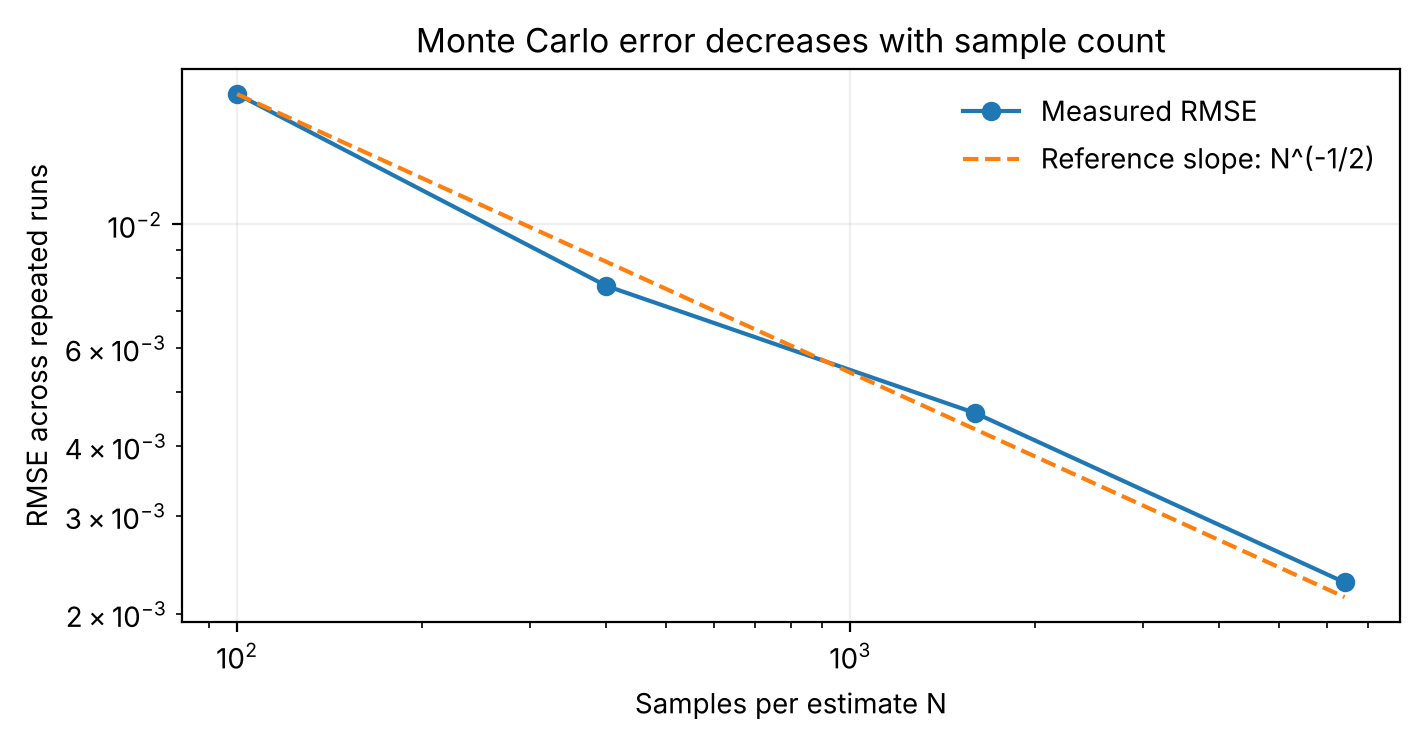

In [15]:
# Create a figure for the empirical error and its reference power law.
fig, ax = plt.subplots()
# Plot measured RMSE against sample count on logarithmic axes.
ax.loglog(sample_sizes, rmse_values, 'o-', label='Measured RMSE')
# Anchor an N^(-1/2) guide at the first observed error value.
reference = [rmse_values[0] * math.sqrt(sample_sizes[0]/n) for n in sample_sizes]
# Plot the theoretical slope as a guide, not as a fitted or exact prediction.
ax.loglog(sample_sizes, reference, '--', label='Reference slope: N^(-1/2)')
# Identify both axes and the type of repeated experiment.
ax.set(xlabel='Samples per estimate N', ylabel='RMSE across repeated runs', title='Monte Carlo error decreases with sample count')
# Label the empirical curve and the slope guide.
ax.legend(frameon=False)
# Add faint guides for reading factors on the logarithmic axes.
ax.grid(alpha=0.2)
# Keep all text and axes inside the figure boundary.
fig.tight_layout()
# Show the repeated-run diagnostic.
plt.show()


### Another view: hit-or-miss integration

Draw points $(X,Y)$ uniformly in the unit square. A point is inside the quarter of a unit disk when $X^2+Y^2\le1$. The fraction inside estimates the *area* $\pi/4$; multiplying by four estimates $\pi$. This is a two-dimensional Monte Carlo integral of an indicator function, not a new formula for $\pi$. It gives another use for Boolean conditions and illustrates that random sampling is not limited to one dimension. For this elementary problem, deterministic methods are generally more efficient.


In [16]:
# Give the two-dimensional area experiment an independent generator.
area_rng = np.random.default_rng(83)
# Set the total number of uniformly sampled square points.
area_count = 8000
# Generate x coordinates uniformly in the unit interval.
area_x = area_rng.random(area_count)
# Generate independent y coordinates uniformly in the unit interval.
area_y = area_rng.random(area_count)
# Mark each point inside the unit quarter-circle with a Boolean value.
inside = area_x**2 + area_y**2 <= 1.0
# Count successful points by summing the Boolean array.
inside_count = int(np.sum(inside))
# Convert the observed area fraction into an estimate of pi.
pi_estimate = 4.0 * inside_count / area_count
# Report the estimate and the known mathematical constant.
print(f'Points inside: {inside_count} of {area_count}')
# Display the two values without implying that they must match exactly.
print(f'Pi estimate {pi_estimate:.5f}; math.pi {math.pi:.5f}')


Points inside: 6263 of 8000
Pi estimate 3.13150; math.pi 3.14159


## 4. Importance sampling: choose points deliberately

Simple sampling draws uniformly, even when the function is very small over much of the interval. Consider $I=\int_0^1 x^4\,dx=1/5=0.2$. Values near $x=1$ contribute more to this integral than values near $x=0$. We may deliberately choose a density $p(x)=3x^2$ on $[0,1]$, which draws more points near one. Its CDF is $F(x)=x^3$, so if $U\sim U(0,1)$, then $X=U^{1/3}$ has density $p$.

**The essential correction:** a point chosen three times more often must carry an appropriately smaller weight. In general,

$$ I=\int_0^1 f(x)\,dx=\int_0^1\frac{f(x)}{p(x)}p(x)\,dx=\mathbb E_p\!\left[\frac{f(X)}{p(X)}\right]. $$

Here $f(x)=x^4$ and $p(x)=3x^2$, so $f(x)/p(x)=x^2/3$ for $x>0$, with limiting value zero at $x=0$. The simplified expression avoids dividing by a zero density in a rare endpoint draw. **Averaging $X^4$ for points drawn from $p$ without dividing by $p(X)$ estimates a different quantity**: $\mathbb E_p[X^4]=3/7$, not $1/5$.


In [17]:
# Define the chosen nonuniform density for numerical inspection.
def proposal_density(x):
    # Return 3*x^2 for x inside the integration interval.
    return 3.0 * x**2
# Define the importance-sampling weight using its simplified safe form.
def importance_weight(x):
    # Use x^2/3, which equals f(x)/p(x) for positive x and extends to x=0.
    return x**2 / 3.0
# Check the proposal integrates to one by an exact elementary calculation.
assert math.isclose(3.0/3.0, 1.0)
# Check the weight identity at an interior point where p(x) is positive.
assert math.isclose(importance_weight(0.5), 0.5**4/proposal_density(0.5))
# Report one transparent calculation: f(0.5)/p(0.5) = (0.5)^2/3.
print('Weight at x=0.5:', round(importance_weight(0.5), 6))


Weight at x=0.5: 0.083333


In [18]:
# Fix one sample size for a direct simple-versus-importance comparison.
comparison_count = 5000
# Give uniform sampling its own independent generator.
uniform_comparison_rng = np.random.default_rng(97)
# Give importance sampling another independent generator.
importance_rng = np.random.default_rng(101)
# Draw uniform points for the ordinary sample-mean estimator.
uniform_points = uniform_comparison_rng.random(comparison_count)
# Transform new uniform draws through F^(-1)(u) = u^(1/3).
important_points = importance_rng.random(comparison_count)**(1.0/3.0)
# Evaluate f(x)=x^4 on uniformly sampled points.
ordinary_values = uniform_points**4
# Evaluate the corrected weight f(x)/p(x)=x^2/3 on proposal points.
weighted_values = importance_weight(important_points)
# Average the ordinary values to estimate the integral over [0,1].
ordinary_estimate = float(np.mean(ordinary_values))
# Average the corrected weights to estimate the same integral.
important_estimate = float(np.mean(weighted_values))
# Estimate the standard error of the uniform estimator from its sample SD.
ordinary_se = float(np.std(ordinary_values, ddof=1)/math.sqrt(comparison_count))
# Estimate the standard error of the weighted estimator from its sample SD.
important_se = float(np.std(weighted_values, ddof=1)/math.sqrt(comparison_count))
# Display the exact value and the two independently generated estimates.
print(f'Exact integral:       {1/5:.6f}')
# Show the ordinary estimate and its estimated run-to-run scale.
print(f'Uniform estimate:    {ordinary_estimate:.6f}; estimated SE {ordinary_se:.6f}')
# Show the corrected importance estimate and its estimated scale.
print(f'Importance estimate: {important_estimate:.6f}; estimated SE {important_se:.6f}')


Exact integral:       0.200000
Uniform estimate:    0.202083; estimated SE 0.003782
Importance estimate: 0.200998; estimated SE 0.001241


The importance estimator's smaller *estimated standard error* is useful evidence, but one run can be lucky or unlucky. A repeated comparison gives a firmer picture. For this particular pair $f,p$, the exact variance of one uniform contribution is $\mathrm{Var}_U(X^4)=1/9-1/25=16/225$. The exact variance of one importance contribution is $\mathrm{Var}_p(X^2/3)=1/21-1/25=4/525$. The ratio of these variances is $28/3\approx9.33$, so the standard error ratio approaches $\sqrt{28/3}\approx3.06$ for equal numbers of independent points. **The $N^{-1/2}$ rate remains the same; the variance constant is smaller.** The computational costs per point may differ in other problems.

Why do we not use an arbitrarily narrow proposal at $x=1$? The density must be positive wherever $f$ contributes, apart from harmless zero-measure endpoints, and large values of $f(X)/p(X)$ can make an estimator very noisy. Importance sampling helps only if the proposal is well chosen and its density can be evaluated.


In [19]:
# Make a new random stream for a many-run algorithm comparison.
replicate_rng = np.random.default_rng(113)
# Select the same point count for both methods in every replicate.
points_per_run = 500
# Use many independent replicates to compare typical rather than one-run error.
replicate_count = 300
# Start separate lists for ordinary and importance estimation errors.
ordinary_errors, importance_errors = [], []
# Repeat the two independently drawn estimates the requested number of times.
for run in range(replicate_count):
    # Draw a fresh uniform array for this replicate's ordinary estimator.
    u = replicate_rng.random(points_per_run)
    # Draw a different independent array for the proposal transformation.
    v = replicate_rng.random(points_per_run)
    # Average u^4 and store its signed difference from the exact answer.
    ordinary_errors.append(float(np.mean(u**4)) - 1.0/5.0)
    # Transform v to p(x)=3*x^2 and average the correctly weighted values.
    importance_errors.append(float(np.mean(importance_weight(v**(1.0/3.0)))) - 1.0/5.0)
# Calculate the empirical RMSE of the ordinary repeated estimates.
ordinary_rmse = math.sqrt(float(np.mean(np.square(ordinary_errors))))
# Calculate the empirical RMSE of the weighted repeated estimates.
important_rmse = math.sqrt(float(np.mean(np.square(importance_errors))))
# Display both empirical scales on the same numerical basis.
print(f'Uniform RMSE across runs:    {ordinary_rmse:.5f}')
# Display the importance scale and the observed improvement factor.
print(f'Importance RMSE across runs: {important_rmse:.5f}')
# Compare the measured ratio to the exact large-sample SE ratio.
print(f'RMSE ratio {ordinary_rmse/important_rmse:.2f}; theory SE ratio {math.sqrt(28/3):.2f}')


Uniform RMSE across runs:    0.01208
Importance RMSE across runs: 0.00443
RMSE ratio 2.73; theory SE ratio 3.06


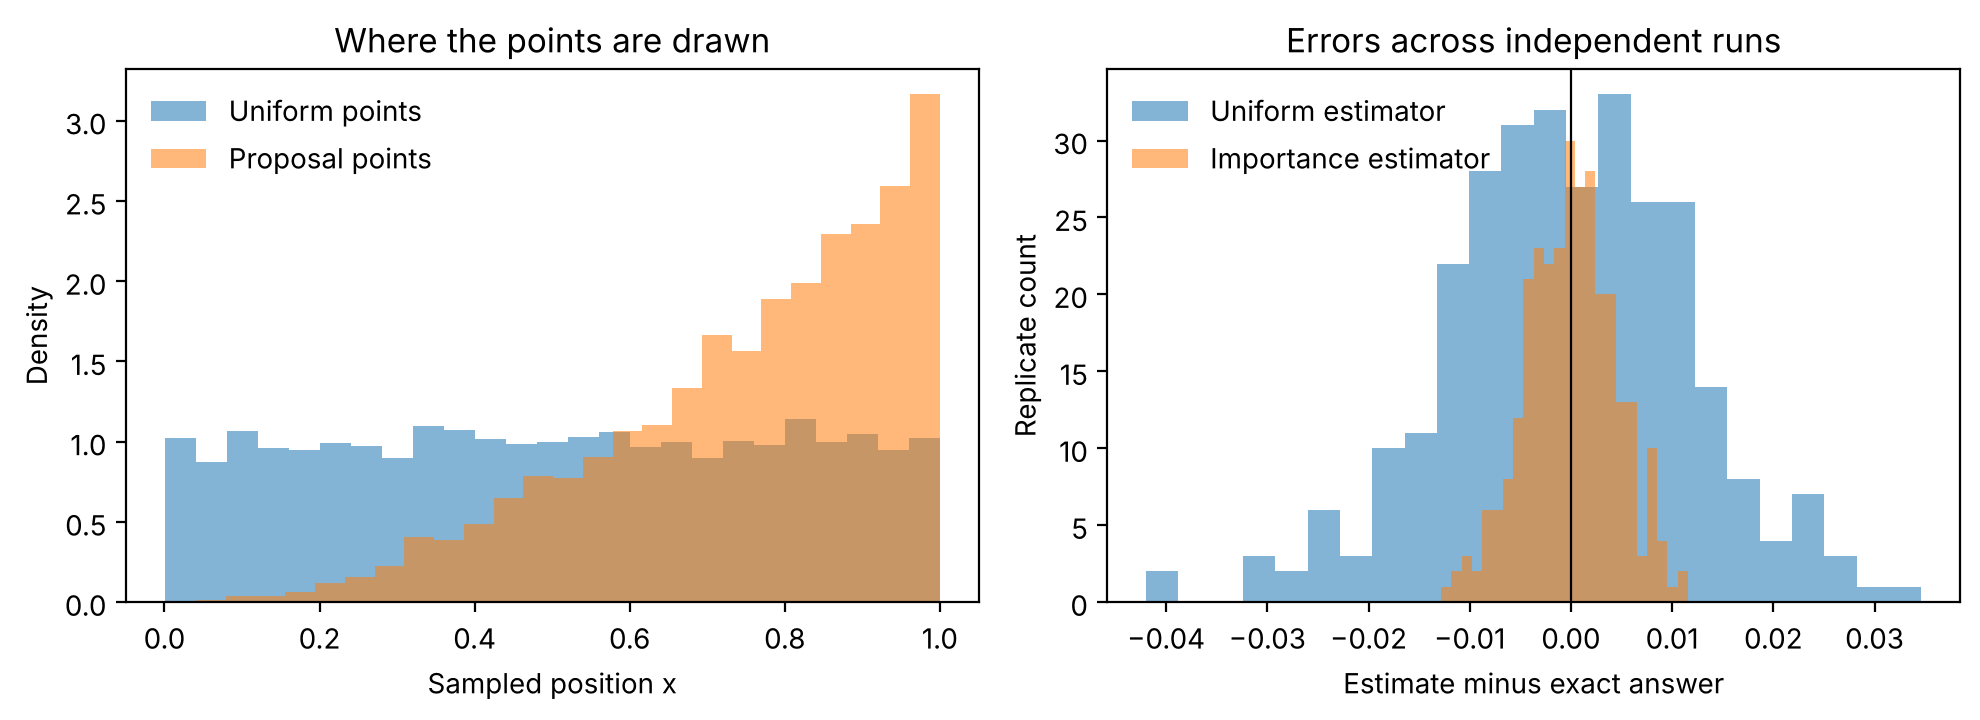

In [20]:
# Create a two-panel figure to relate point placement to estimation error.
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.7))
# Plot the histogram of points sampled uniformly on [0,1].
axes[0].hist(uniform_points, bins=25, density=True, alpha=0.55, label='Uniform points')
# Plot the histogram of proposal points, which concentrate toward x=1.
axes[0].hist(important_points, bins=25, density=True, alpha=0.55, label='Proposal points')
# Label the first panel as a comparison of sampling locations.
axes[0].set(xlabel='Sampled position x', ylabel='Density', title='Where the points are drawn')
# Identify the two sets of sampled points.
axes[0].legend(frameon=False)
# Make a histogram of repeated ordinary estimation errors.
axes[1].hist(ordinary_errors, bins=24, alpha=0.55, label='Uniform estimator')
# Overlay the repeated weighted errors on the same horizontal scale.
axes[1].hist(importance_errors, bins=24, alpha=0.55, label='Importance estimator')
# Mark zero error as a reference for interpreting both histograms.
axes[1].axvline(0.0, color='black', linewidth=0.8)
# Explain the second panel's horizontal and vertical quantities.
axes[1].set(xlabel='Estimate minus exact answer', ylabel='Replicate count', title='Errors across independent runs')
# Identify each error distribution.
axes[1].legend(frameon=False)
# Avoid clipped labels between the two panels.
fig.tight_layout()
# Display the comparison figure.
plt.show()


## 5. A general interval and a common mistake

For $X\sim U(a,b)$, the interval width must appear in the estimator: $\hat I=(b-a)\,\overline{f(X)}$. For any normalized proposal density $p$ on an interval containing all nonzero contributions, the importance estimator is $\hat I_p=N^{-1}\sum f(X_i)/p(X_i)$, with $X_i\sim p$. The density already carries the units of inverse length, so there is **no extra $(b-a)$ factor** in this latter formula. Uniform sampling is a special case of importance sampling with $p=1/(b-a)$.

To test the width factor, estimate $\int_2^5 x\,dx=(5^2-2^2)/2=10.5$. A draw on $[2,5]$ can be made as $X=2+3U$.


In [21]:
# Define the left endpoint of the integration interval.
left = 2.0
# Define the right endpoint and therefore the interval length.
right = 5.0
# Create a separate generator for this width-factor check.
interval_rng = np.random.default_rng(127)
# Draw 10000 uniform points and shift-scale them into [2,5).
interval_points = left + (right-left)*interval_rng.random(10000)
# Multiply the mean of f(x)=x by the interval width.
interval_estimate = (right-left)*float(np.mean(interval_points))
# Compute the analytic integral of x on [2,5].
interval_exact = (right**2-left**2)/2.0
# Show the approximation and its exact benchmark.
print(f'Integral of x from 2 to 5: estimate {interval_estimate:.4f}; exact {interval_exact:.4f}')


Integral of x from 2 to 5: estimate 10.5181; exact 10.5000


## 6. Questions for independent study

1. **Trace a variable and a list.** What are the types of `faces[0]`, `probabilities[0]`, `same_sequence`, and `function_values`? What does `function_values[0]` store?
2. **Predict a branch.** For the biased die, which face is returned when `u=0.25`? Identify the comparison that selects it. Why does `sample_die(1.0)` raise an error?
3. **Change the rate.** Set the exponential rate to 4, regenerate the values, and predict both the theoretical mean and $P(X\le1)$. Repeat with a fresh seed and compare empirical values.
4. **Test the inverse CDF.** For $U=0.75$ and rate 2, compute $X$ with a calculator and confirm $F(X)=0.75$.
5. **Find a coding error.** Remove the factor `right-left` from `interval_estimate`. What quantity is then being estimated, and why is it not the integral?
6. **Inspect an importance error.** Replace `np.mean(importance_weight(important_points))` with `np.mean(important_points**4)`. Toward which theoretical value should it converge, and why is that not $1/5$?
7. **Design another example.** Estimate $\int_0^1 x^2\,dx=1/3$ first with uniform points, then with $p(x)=2x$ and $X=\sqrt U$. Write the correct importance weight, including its value at zero.
8. **Interpret variability.** Run the simple estimator with seeds 1, 2, and 3. Do three errors have to be smaller than the displayed estimated standard error? Explain what an estimated standard error does and does not tell you.

**Answers to check reasoning.** In Question 2, $u=0.25$ lies on the endpoint after face 3 and is assigned to face 4 because the comparison is strict `<`; `u=1` is outside the allowed half-open interval. In Question 3 the mean is $1/4$, while $P(X\le1)=1-e^{-4}$. In Question 4, $X=-\log(0.25)/2=\log 2$, and $F(X)=1-e^{-2\log2}=0.75$. In Question 5 the unmultiplied average estimates $\mathbb E[X]=3.5$, not the area 10.5. In Question 6 the wrong average tends to $\mathbb E_p[X^4]=3/7$. In Question 7 the weight is $x^2/(2x)=x/2$ for $x>0$, with limiting value zero at $x=0$. In Question 8 an SE is a run-to-run scale estimate, not an error limit that each run must obey.

## 7. What the experiment establishes

The code demonstrates how to map uniform pseudo-random numbers into discrete and continuous distributions, how an integral can be expressed as an expectation, and why deliberate nonuniform sampling requires a probability-density correction. The two integration benchmarks are known exactly so that mistakes can be detected. Repeated estimates make the distinction between a realized error and an error scale visible.

These short one-dimensional examples do not imply that Monte Carlo is the best way to compute a smooth elementary integral. They are chosen because the method extends to complicated, higher-dimensional problems. Importance sampling can reduce variance, but does not automatically do so; the proposal must match the integrand while remaining usable wherever the integrand contributes. The optional acceptance/rejection sampler draws from a target distribution but is separate from the integral-estimation formula.

**Source and next reading.** The author's slides *Monte Carlo Method, Parts 1 and 2* (Wang, 2025) introduce inverse-transform and rejection sampling, simple sampling, and importance sampling. For a second programming exercise, change the integrand and derive its exact benchmark before running the simulation. More advanced normal sampling, Markov-chain Monte Carlo, and many-particle configuration integrals can be studied after these foundations.


## Optional extensions: the same examples, more Python ideas

The following short extensions use the same examples to revisit programming ideas that do not belong in the first pass through Monte Carlo integration. They are **not prerequisites** for Sections 1–7. The code remains executable in sequence so that a student can return later, use *Run All*, and inspect every result.

### Types, output labels, round-off, and numerical bisection

An algorithm is an imperative recipe: draw a number, transform it, evaluate a function, update an estimate. The statement $I=\mathbb E[f(X)]$ is declarative mathematical knowledge; the `for` loop and arithmetic statements describe how to obtain an approximation. Python evaluates expressions according to precedence, so `2 + 3**2` is 11 whereas `(2 + 3)**2` is 25. Division `/` produces a float; `//` and `%` divide an integer number of samples into full batches and a remainder. A variable name is bound to a value with a type, not fixed forever to a single type. `None` can represent a missing result, but it is not a numerical zero.

The notebook uses no live `input()` call because that would interrupt *Run All*. A separate interactive script could ask for a count using `int(input('How many samples? '))`, then check `count > 0` before allocating an array. A missing parenthesis is a syntax error; calculating the wrong importance weight is a semantic error that can run normally and requires a test against a known answer.


In [22]:
# Keep the count as an integer so it can be used by range() or an array size.
requested_samples = 23
# Choose an integer batch size for a simple bookkeeping example.
batch_size = 5
# Count complete batches using integer floor division.
full_batches = requested_samples // batch_size
# Count leftover observations using the remainder operator.
leftover = requested_samples % batch_size
# Bind a Boolean that records whether a smaller final batch is needed.
needs_final_batch = leftover > 0
# Bind a string label for a printed numerical report.
report_label = 'simple sampling: N=23'
# Use None to mean that an optional result has not yet been calculated.
optional_result = None
# Display values and names of all five basic Python types in this example.
print([(type(value).__name__, value) for value in [requested_samples, 0.5, needs_final_batch, report_label, optional_result]])
# Display the meaning of // and % for dividing work into batches.
print(f'{requested_samples} samples = {full_batches} full batches and {leftover} extra samples')
# Check that these two integer operations reconstruct the original count.
assert full_batches*batch_size + leftover == requested_samples
# Select a message using the three possible remainder cases.
if leftover == 0:
    # A zero remainder means no final partial batch is needed.
    batch_message = 'All batches are complete.'
# A remainder of one calls for a final single observation.
elif leftover == 1:
    # Store a message specific to a one-observation partial batch.
    batch_message = 'One observation remains.'
# All other positive remainders need a larger partial batch.
else:
    # Include the actual remainder in the string for this example.
    batch_message = f'{leftover} observations remain.'
# Display the branch chosen for the requested sample count.
print(batch_message)


[('int', 23), ('float', 0.5), ('bool', True), ('str', 'simple sampling: N=23'), ('NoneType', None)]
23 samples = 4 full batches and 3 extra samples
3 observations remain.


Strings help label an experiment but do not change its numerical result. A string is immutable: methods such as `replace` return a new string. Slicing uses a starting index that is included and an ending index that is excluded. Keep text processing outside a large numerical inner loop when possible.


In [23]:
# Split the existing label at its colon into two strings.
label_parts = report_label.split(':')
# Strip the leading space, then convert the method name to uppercase.
method_name = label_parts[0].upper()
# Locate the first position of the word sampling in the original label.
word_position = report_label.find('sampling')
# Build a revised label without changing the immutable original string.
revised_label = report_label.replace('simple', 'uniform')
# Print indexed, sliced and transformed forms to inspect the string operations.
print('First character:', report_label[0], '; first six:', report_label[:6])
# Confirm the old and new labels are separate values.
print('Original:', report_label, '; revised:', revised_label)
# Display the uppercased first field and the character position found.
print('Method:', method_name, '; sampling starts at index:', word_position)


First character: s ; first six: simple
Original: simple sampling: N=23 ; revised: uniform sampling: N=23
Method: SIMPLE SAMPLING ; sampling starts at index: 7


The exponential example has an analytic inverse CDF, but an engineering model may give only a function that can be evaluated. Bisection then finds $x$ satisfying $F(x)=u$ by repeatedly keeping the half-interval containing the solution. This demonstration solves **one** problem with $u=0.75$; it does not suggest running a Python bisection loop for every draw when the exact inverse is available. We compare with a tolerance rather than demanding equality of independently computed floating-point answers.


In [24]:
# Select one target cumulative probability for a numerical inversion.
target_u = 0.75
# Bracket the answer, knowing the exponential CDF starts at zero.
lower_x = 0.0
# Choose a high endpoint whose CDF exceeds this particular target.
upper_x = 4.0
# Stop when the uncertainty in x is below a practical tolerance.
tolerance = 1e-9
# Count halvings to relate bisection to logarithmic convergence.
halvings = 0
# Verify the upper endpoint really brackets the desired cumulative value.
assert 1.0 - math.exp(-rate*upper_x) > target_u
# Continue halving until the bracket is narrow enough.
while upper_x - lower_x > tolerance:
    # Find the midpoint of the current bracket.
    middle_x = (lower_x + upper_x)/2.0
    # Evaluate the exponential cumulative distribution at the midpoint.
    middle_probability = 1.0 - math.exp(-rate*middle_x)
    # The root lies to the right if the midpoint probability is too small.
    if middle_probability < target_u:
        # Replace the low endpoint with the current midpoint.
        lower_x = middle_x
    # Otherwise the root lies in the left half, including the midpoint.
    else:
        # Replace the high endpoint with the current midpoint.
        upper_x = middle_x
    # Record how many interval halvings were required.
    halvings += 1
# Use the midpoint of the final short bracket as the numerical answer.
bisection_x = (lower_x + upper_x)/2.0
# Calculate the analytic inverse for an independent check.
analytic_x = exponential_from_uniform(target_u, rate)
# Print both answers and the number of halvings.
print(f'Bisection x={bisection_x:.10f}; analytic x={analytic_x:.10f}; halvings={halvings}')
# Use a tolerance because the two floats need not be bit-for-bit equal.
assert math.isclose(bisection_x, analytic_x, abs_tol=tolerance)


Bisection x=0.6931471801; analytic x=0.6931471806; halvings=32


### Function interfaces, lists, dictionaries, and tests

The docstring of `sample_die(u)` states what the function promises; its caller need not know the internal cumulative-list scan. Parameters such as `u` are local names created for a call, whereas the `faces` and `cumulative` lists are read from the enclosing notebook scope. For a reusable library, those lists would be passed as arguments or packaged in a class, as in the later extension. `return` supplies a value to the caller; `print` merely displays it. `exponential_from_uniform(0.5, rate=2.0)` illustrates a keyword argument.

The paired lists `faces` and `probabilities` depend on matching **zero-based indices**. `counts[face]` is different: it looks up a dictionary by an immutable integer key. `counts.items()` visits key-value pairs; `counts.values()` supplies just the counts. A tuple can pack a result with its uncertainty estimate and then unpack both. A list can be modified through more than one name, so copy it before experimenting with mutations. In the next cell, `append` and `pop` change the aliased list, `sorted` produces a separate ordered list, and `[-1]` selects its last element.


In [25]:
# Pack a numerical estimate and its SE into an immutable two-element tuple.
result_pair = (simple_estimate, simple_se)
# Unpack the two tuple positions into names with distinct interpretations.
estimate_again, error_scale_again = result_pair
# Make a short new list that records two die counts for an aliasing experiment.
short_counts = [counts[1], counts[6]]
# Bind another name to the same mutable list object without copying it.
alias_counts = short_counts
# Make an independent shallow copy of the list of immutable integers.
copied_counts = short_counts.copy()
# Append a summary to the alias, which necessarily changes the original list.
alias_counts.append(sum(short_counts))
# Show that the copy did not acquire the newly appended summary.
print('Original through alias:', short_counts, '; independent copy:', copied_counts)
# Remove and return the appended summary without changing the separate copy.
removed_summary = alias_counts.pop()
# Display the restored original list and the value returned by pop().
print('After pop:', short_counts, '; removed summary:', removed_summary)
# Sort the independent ten-value integration sample for an order-statistic example.
sorted_values = sorted(function_values)
# Inspect its minimum and maximum by zero and negative-one indices.
print('Small-sample range:', round(sorted_values[0], 4), round(sorted_values[-1], 4))
# Iterate over the main count dictionary as face-count pairs.
print('Dictionary items:', list(counts.items()))
# Demonstrate named tuple positions without confusing SE with realized error.
print(f'Unpacked estimate {estimate_again:.6f}; SE {error_scale_again:.6f}')
# Verify the two names refer to the same original list while the copy is separate.
assert alias_counts is short_counts and copied_counts is not short_counts


Original through alias: [1017, 3931, 4948] ; independent copy: [1017, 3931]
After pop: [1017, 3931] ; removed summary: 4948
Small-sample range: 0.3685 0.9889
Dictionary items: [(1, 1017), (2, 1027), (3, 968), (4, 2079), (5, 2978), (6, 3931)]
Unpacked estimate 0.630876; SE 0.001804


Recursion is not needed to draw independent samples: a loop communicates that repeated operation more directly. A short probability calculation nevertheless permits a meaningful comparison. Face 6 of **this biased die** has probability $1/3$, so each throw avoids it with probability $2/3$. The probability of avoiding 6 in $n$ independent throws is $(2/3)^n$. The recursive version uses a base case at $n=0$ and one call on $n-1$; the iterative version keeps a single running value. Both take $O(n)$ arithmetic, but recursive calls use additional stack space and may hit Python's recursion limit for large $n$. This recurrence has no repeated subproblems, so memoization would add overhead here; dictionaries become valuable for recurrences that revisit the same arguments, such as a naive recursive Fibonacci function.


In [26]:
# Define a small recursive probability function with a clear base case.
def probability_no_six_recursive(n):
    # Reject a negative count, for which a number of throws is meaningless.
    if n < 0:
        # Explain the invalid input to a caller.
        raise ValueError('Number of throws must be nonnegative.')
    # With no throws, avoiding a six is certain.
    if n == 0:
        # Return the base-case probability without further recursion.
        return 1.0
    # Multiply one no-six factor by the answer for n-1 earlier throws.
    return (1.0-probabilities[5])*probability_no_six_recursive(n-1)
# Set a deliberately small n for a hand-checkable comparison.
throw_count = 10
# Initialize the iterative probability for zero throws.
iterative_probability = 1.0
# Repeat the same no-six factor once for every throw.
for throw in range(throw_count):
    # Update the running product using the dictionary-free scalar calculation.
    iterative_probability *= 1.0-probabilities[5]
# Compare recursion, iteration and direct exponentiation for ten throws.
print(probability_no_six_recursive(throw_count), iterative_probability, (2/3)**throw_count)
# Require numerical agreement without assuming bit-for-bit equality in all implementations.
assert math.isclose(probability_no_six_recursive(throw_count), iterative_probability)


0.01734152991583263 0.01734152991583263 0.017341529915832606


The earlier boundary checks are **unit tests** of individual samplers; the exact-integral comparisons are **integration checks** of drawing, transformation and averaging together. The repeated-run fixed-seed result can serve as a limited **regression test** after refactoring, although exact sequences can change across software environments. A black-box test uses the function's specification (for example, `sample_die(1.0)` must fail). A glass-box test chooses an input on a cumulative boundary because we know the internal `<` branch. Debugging starts by reproducing the failing input and reading its traceback; an `assert` should check an internal expectation, while user input should be validated with an exception that remains active even if assertions are disabled.


In [27]:
# Begin a controlled test of an invalid exponential-sampler input.
try:
    # Deliberately pass the excluded endpoint one to exercise validation.
    exponential_from_uniform(1.0, rate=2.0)
# Catch the specific exception promised by the sampler's interface.
except ValueError as error:
    # Display the informative message without stopping the notebook.
    print('Expected ValueError:', error)
# Run this branch only if the sampler unexpectedly accepted the bad value.
else:
    # Fail the test if no exception was raised at the boundary.
    raise AssertionError('The sampler accepted u=1.0 unexpectedly.')
# Execute this cleanup/reporting branch in either outcome.
finally:
    # Mark the end of the boundary test for students tracing control flow.
    print('Boundary test complete.')


Expected ValueError: The uniform input must satisfy 0 <= u < 1.
Boundary test complete.


### An optional class interface

The core notebook uses functions because they make the mathematics easiest to inspect. An object can instead keep a generator's *state* alongside a sampling operation. In the optional example, `__init__` constructs the object; `self` names that particular instance; `_rng` and `_seed` are internal attributes by convention, not inaccessible secrets. `get_seed` and `set_seed` provide an interface for reading and resetting the seed. The class variable `created` counts instances. `ExponentialSampler` inherits the generator management, calls `super()`, and **overrides** `sample` with the inverse-CDF transformation. The short example illustrates the vocabulary of classes without making OOP a prerequisite for Monte Carlo integration.


In [28]:
# Define a class that keeps generator state with its sampling operation.
class UniformSampler:
    # Count objects created from this family of sampler classes.
    created = 0
    # Initialize one object's internal generator and seed.
    def __init__(self, seed):
        # Save the seed by an internal attribute naming convention.
        self._seed = seed
        # Create a generator owned by this specific object.
        self._rng = np.random.default_rng(seed)
        # Update a shared class counter for this teaching demonstration.
        UniformSampler.created += 1
    # Provide a small public method that draws n uniform values.
    def sample(self, n=1):
        # Validate n before allocating an array of samples.
        if n <= 0:
            # Report an invalid request instead of producing an empty sample.
            raise ValueError('Sample count must be positive.')
        # Return n draws from this object's saved generator state.
        return self._rng.random(n)
    # Expose the stored seed without exposing generator internals.
    def get_seed(self):
        # Return this object's seed as a regular Python value.
        return self._seed
    # Reset both the seed attribute and the corresponding generator state.
    def set_seed(self, seed):
        # Record the new seed on this particular object.
        self._seed = seed
        # Restart this object's stream from the requested seed.
        self._rng = np.random.default_rng(seed)
    # Give the object a concise human-readable description.
    def __str__(self):
        # Include the class name and current seed in the display text.
        return f'{self.__class__.__name__}(seed={self._seed})'
# Extend the uniform class with a particular nonuniform sampling rule.
class ExponentialSampler(UniformSampler):
    # Initialize both the inherited generator and the new rate.
    def __init__(self, seed, rate):
        # Require a positive exponential rate at construction time.
        if rate <= 0:
            # Explain an invalid distribution parameter.
            raise ValueError('Rate must be positive.')
        # Let the parent class initialize generator state and count the object.
        super().__init__(seed)
        # Save the additional rate on this instance.
        self._rate = rate
    # Override the parent's uniform-sampling method.
    def sample(self, n=1):
        # Reuse the parent method and its input check to draw uniforms.
        uniforms = super().sample(n)
        # Transform those draws through the exponential inverse CDF.
        return -np.log(1.0-uniforms)/self._rate
# Create one object of the original uniform class.
uniform_object = UniformSampler(seed=151)
# Create one subclass object with an exponential rate of two.
exponential_object = ExponentialSampler(seed=157, rate=2.0)
# Print their descriptive interfaces and the shared number of objects.
print(str(uniform_object), str(exponential_object), 'objects:', UniformSampler.created)
# Draw a few values through each object's same-named public method.
print('Uniform:', np.round(uniform_object.sample(3), 3))
# Show that the overridden method yields positive exponential samples.
print('Exponential:', np.round(exponential_object.sample(3), 3))
# Restart the first object's random stream using its setter.
uniform_object.set_seed(151)
# Verify that its seed getter reports the reset value.
assert uniform_object.get_seed() == 151


UniformSampler(seed=151) ExponentialSampler(seed=157) objects: 2
Uniform: [0.492 0.36  0.709]
Exponential: [0.153 0.99  0.25 ]


### Operation counts, searching, and engineering tools

For $N$ requested samples, a loop that performs one constant amount of work per sample is $O(N)$ in time. The die sampler scans at most $K$ cumulative endpoints per draw, so its general cost is $O(NK)$; for this fixed six-face die, $K=6$ and the cost is effectively linear in $N$. Saving all draws takes $O(N)$ memory, while keeping only six counts takes $O(K)$ additional memory. NumPy's array operations are still $O(N)$ for this task, though the compiled inner loops often reduce the constant cost compared with a Python loop. Timing a particular machine is useful but does not change the mathematical order of growth.

The cumulative endpoints are **already sorted** because probabilities are nonnegative. Our original `for` loop is a linear search. Bisection search finds the first endpoint strictly greater than $u$ with $O(\log K)$ comparisons. For only six faces, extra Python bookkeeping may make it slower; the asymptotic comparison matters as $K$ grows. Sorting an unsorted list before one lookup would cost more than this tiny search. The algorithm uses integer midpoint `//` and the same strict boundary convention as `sample_die`.


In [29]:
# Define a bisection search on sorted cumulative probability endpoints.
def sample_die_bisection(u):
    # Reject uniform inputs outside the half-open interval.
    if not 0.0 <= u < 1.0:
        # Keep the same public boundary behavior as the linear sampler.
        raise ValueError('The uniform input must satisfy 0 <= u < 1.')
    # Start the candidate index range just before the first endpoint.
    low_index = 0
    # Use a half-open search range ending after the last endpoint.
    high_index = len(cumulative)
    # Halve the candidate index range until exactly one position remains.
    while low_index < high_index:
        # Use integer division to choose an index within the candidate range.
        middle_index = (low_index + high_index)//2
        # Keep the left half if the middle endpoint is greater than u.
        if u < cumulative[middle_index]:
            # The desired endpoint lies at or to the left of the midpoint.
            high_index = middle_index
        # Otherwise skip the midpoint and all endpoints to its left.
        else:
            # Continue searching to the right for a strictly greater endpoint.
            low_index = middle_index + 1
    # Retrieve the face aligned with the first endpoint strictly above u.
    return faces[low_index]
# Check one exact boundary that distinguishes < from <=.
assert sample_die_bisection(0.25) == sample_die(0.25) == 4
# Create a separate stream of test inputs for regression comparison.
search_test_rng = np.random.default_rng(163)
# Compare both implementations on many uniformly distributed inputs.
for test_u in search_test_rng.random(500):
    # Fail if either search assigns the value to a different die face.
    assert sample_die_bisection(float(test_u)) == sample_die(float(test_u))
# Report the conceptual comparison, avoiding a fragile speed-up claim.
print('Linear and bisection searches agree on 500 draws and the boundary 0.25.')


Linear and bisection searches agree on 500 draws and the boundary 0.25.


A final complexity comparison: reading one indexed array element is $O(1)$; bisection search among $K$ sorted endpoints is $O(\log K)$; a sample loop is $O(N)$; comparison sorting is generally $O(N\log N)$; comparing all pairs of $N$ observations is $O(N^2)$. A naive recursive Fibonacci program can take exponential time, while caching repeated subproblems in a dictionary changes its work markedly. These are *different algorithms*; they are not all part of this Monte Carlo estimator.

The numerical work in this notebook uses Python for organization, NumPy for vectorized numerical arrays, and Matplotlib for figures. SciPy has additional probability and integration routines, but is not required here. An engineer could implement the same mathematical estimator in MATLAB, C++, or another language. The choice concerns the task, available libraries, performance requirements and maintainability; the correction factor $f/p$ does not depend on programming language. Before making a performance claim, measure code with the same workload and count its main operations.


In [30]:
# Import a high-resolution clock for a small illustrative scaling check.
import time
# Choose increasing numbers of repeated die draws.
timing_sizes = [1000, 4000, 16000]
# Use a dedicated generator so the timed comparison is reproducible in its inputs.
timing_rng = np.random.default_rng(173)
# Save the elapsed time measured at each requested sample size.
timing_seconds = []
# Measure one execution at each requested size without assuming exact ratios.
for timing_n in timing_sizes:
    # Prepare the random inputs before starting the timed Python search loop.
    timing_draws = timing_rng.random(timing_n)
    # Start the clock immediately before the loop's actual work.
    start_time = time.perf_counter()
    # Search each draw's face using the original linear implementation.
    timing_faces = [sample_die(float(u)) for u in timing_draws]
    # Measure elapsed time after all face selections are complete.
    elapsed = time.perf_counter()-start_time
    # Store the measured time so it can be inspected later.
    timing_seconds.append(elapsed)
    # Confirm that every input yielded one output face.
    assert len(timing_faces) == timing_n
    # Print the elapsed measurement for this particular machine and run.
    print(f'{timing_n:5d} selections: {elapsed*1000:.2f} ms')


 1000 selections: 0.46 ms
 4000 selections: 1.77 ms
16000 selections: 6.92 ms


**Final reading check.** The optional class, bisection and timing examples change the *organization* of a program, not the probability law. The main statistical distinction remains: if the sampling density changes from uniform to $p(x)$, the integrand contribution must be weighted by $1/p(x)$. Re-run the notebook from the top after editing a preceding cell, because Jupyter retains variables from earlier executions and out-of-order execution can hide a mistake.
